# Assignment: Video Quality Inference

To this point in the class, you have learned various techniques for leading and analyzing packet captures of various types, generating features from those packet captures, and training and evaluating models using those features.

In this assignment, you will put all of this together, using a network traffic trace to train a model to automatically infer video quality of experience from a labeled traffic trace.

## Getting the data

Everything you need is in the course data repository on GitHub, [noise-courses/data](https://github.com/noise-courses/data), under `video-qoe/`. Either clone the whole repository (about 110 MB):

```
git clone https://github.com/noise-courses/data.git
```

or fetch just the files you need with the `wget` lines given in each part below. The four files are:

| File | Used in | Size |
|---|---|---|
| `netflix.pcap` | Part 1 | 22 MB |
| `netflix_dataset.pkl.xz` *or* `video_dataset.pkl.xz` | Part 2 | 22 MB / 61 MB compressed |
| `netflix_session.pkl` | Part 3 | 130 KB |

## Part 1: Warmup

The first part of this assignment builds directly on the hands-on activities but extends them slightly.

### Extract Features from the Network Traffic

Load the `netflix.pcap` file, which is a packet trace that includes network traffic:

```
!wget https://raw.githubusercontent.com/noise-courses/data/main/video-qoe/netflix.pcap
```



In [1]:
!wget https://raw.githubusercontent.com/noise-courses/data/main/video-qoe/netflix.pcap

--2026-10-28 03:49:42--  https://raw.githubusercontent.com/noise-courses/data/main/video-qoe/netflix.pcap
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 23394717 (22M) [application/octet-stream]
Saving to: ‘netflix.pcap’

netflix.pcap        100%[===================>]  22.31M  76.6MB/s    in 0.3s    

2026-10-28 03:49:43 (76.6 MB/s) - ‘netflix.pcap’ saved [23394717/23394717]



### Identifying the Service Type

Use the DNS traffic to filter the packet trace for Netflix traffic.

In [11]:

from scapy.all import PcapReader, DNS

netflix_domains = (
    "netflix.com",
    "netflix.net",
    "nflxvideo.net",
    "nflximg.net",
    "nflxso.net",
    "nflxext.com",
)

def is_netflix_domain(name):
    name = name.rstrip(".").lower()
    return any(
        name == domain or name.endswith("." + domain)
        for domain in netflix_domains
    )

netflix_names = set()
netflix_ips = set()

with PcapReader("netflix.pcap") as capture:
    for packet in capture:
        if DNS not in packet:
            continue

        dns = packet[DNS]

        try:
            question = dns.qd
            if question is not None:
                qname = question.qname.decode(
                    "utf-8", errors="ignore"
                ).rstrip(".").lower()

                if is_netflix_domain(qname):
                    netflix_names.add(qname)
        except (AttributeError, IndexError):
            pass

        try:
            answers = dns.an
            for record in answers:
                rrname = record.rrname.decode(
                    "utf-8", errors="ignore"
                ).rstrip(".").lower()

                if is_netflix_domain(rrname):
                    netflix_names.add(rrname)

                    if record.type == 1:
                        netflix_ips.add(record.rdata)


                if record.type == 5:
                    cname = record.rdata.decode(
                        "utf-8", errors="ignore"
                    ).rstrip(".").lower()

                    if is_netflix_domain(cname):
                        netflix_names.add(cname)

        except (AttributeError, IndexError, TypeError):
            pass

print("Netflix DNS names:", len(netflix_names))
for name in sorted(netflix_names):
    print(" ", name)

print("\nCandidate IPv4 addresses:", len(netflix_ips))
for ip in sorted(netflix_ips, key=str):
    print(" ", ip)


Netflix DNS names: 17
  assets.nflxext.com
  codex.nflxext.com
  customerevents.eu-west-1.prodaa.netflix.com
  customerevents.netflix.com
  ipv4-c001-cdg001-ix.1.oca.nflxvideo.net
  ipv4-c005-cdg001-ix.1.oca.nflxvideo.net
  ipv4-c024-cdg001-ix.1.oca.nflxvideo.net
  ipv4-c063-cdg001-ix.1.oca.nflxvideo.net
  ipv4-c069-cdg001-ix.1.oca.nflxvideo.net
  ipv4-c071-cdg001-ix.1.oca.nflxvideo.net
  ipv4-c072-cdg001-ix.1.oca.nflxvideo.net
  occ-0-56-55.1.nflxso.net
  push.prod.eu-west-1.prodaa.netflix.com
  push.prod.netflix.com
  tp-s.nflximg.net
  www.eu-west-1.prodaa.netflix.com
  www.netflix.com

Candidate IPv4 addresses: 15
  198.38.120.130
  198.38.120.134
  198.38.120.137
  198.38.120.153
  198.38.120.162
  198.38.120.164
  198.38.120.166
  198.38.120.167
  34.252.77.54
  52.19.39.146
  52.208.128.101
  52.210.133.255
  52.210.19.176
  52.48.148.78
  52.48.8.150


### Generate Statistics

Generate statistics and features for the Netflix traffic flows. Use the `netml` library or any other technique that you choose to generate a set of features that you think would be good features for your model.

In [3]:

from netml.pparser.parser import PCAP

pcap = PCAP(
    "netflix.pcap",
    flow_ptks_thres=2,
    random_state=42,
    verbose=10,
)

pcap.pcap2flows()

print("Flows extracted:", len(pcap.flows))


/usr/local/lib/python3.13/dist-packages/scapy/layers/ipsec.py:512: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from cryptography.hazmat.primitives.ciphers.algorithms in 48.0.0.
  cipher=algorithms.TripleDES,
/usr/local/lib/python3.13/dist-packages/scapy/layers/ipsec.py:516: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from cryptography.hazmat.primitives.ciphers.algorithms in 48.0.0.
  cipher=algorithms.TripleDES,


pcap_file: netflix.pcap
ith_packets: 0
ith_packets: 10000
ith_packets: 20000
ith_packets: 30000
ith_packets: 40000
ith_packets: 50000
ith_packets: 60000
ith_packets: 70000
ith_packets: 80000
ith_packets: 90000
ith_packets: 100000
ith_packets: 110000
ith_packets: 120000
ith_packets: 130000
ith_packets: 140000
len(flows): 275
total number of flows: 275. Num of flows < 2 pkts: 91, and >=2 pkts: 184 without timeout splitting.
kept flows: 184. Each of them has at least 2 pkts after timeout splitting.
flow_durations.shape: (184, 1)
        col_0
count 184.000
mean   82.331
std   127.700
min     1.138
25%    14.428
50%    17.122
75%    71.087
max   486.705
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 184 entries, 0 to 183
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   col_0   184 non-null    float64
dtypes: float64(1)
memory usage: 1.6 KB
None
0th_flow: len(pkts): 12
After splitting flows, the number of subflows: 184 and eac

In [4]:

pcap.flow2features("STATS", fft=False, header=False)

features = pcap.features

print("Feature matrix shape:", features.shape)
print("First five flow feature vectors:")
print(features[:5])


True
Feature matrix shape: (184, 12)
First five flow feature vectors:
[[1.14615760e+01 1.04697644e+00 9.35298951e+01 8.93333333e+01
  4.96006272e+01 6.60000000e+01 6.60000000e+01 6.90000000e+01
  6.60000000e+01 2.00000000e+02 1.20000000e+01 1.07200000e+03]
 [2.48797163e+02 2.69295675e-01 2.22832123e+01 8.27462687e+01
  4.19218688e+01 6.60000000e+01 6.60000000e+01 6.60000000e+01
  5.40000000e+01 2.00000000e+02 6.70000000e+01 5.54400000e+03]
 [1.93497229e+01 2.58401634e-01 1.76746717e+01 6.84000000e+01
  4.80000000e+00 6.60000000e+01 6.60000000e+01 6.60000000e+01
  6.60000000e+01 7.80000000e+01 5.00000000e+00 3.42000000e+02]
 [1.93494620e+01 2.58405117e-01 1.76749100e+01 6.84000000e+01
  4.80000000e+00 6.60000000e+01 6.60000000e+01 6.60000000e+01
  6.60000000e+01 7.80000000e+01 5.00000000e+00 3.42000000e+02]
 [3.00745291e+02 9.64271125e-02 8.72499114e+00 9.04827586e+01
  4.76825861e+01 6.60000000e+01 6.60000000e+01 1.04000000e+02
  5.40000000e+01 2.00000000e+02 2.90000000e+01 2.62400000e

**Write a brief justification for the features that you have chosen.**

I chose the `STATS` features because flow duration, packet sizes, byte counts, and traffic rates help characterize network behavior and identify patterns associated with video streaming. I will also use segment download rates to help infer video quality.

### Inferring Segment downloads

In addition to the features that you could generate using the `netml` library or similar, add to your feature vector a "segment downloads rate" feature, which indicates the number of video segments downloaded for a given time window.

Note: If you are using the `netml` library, generating features with `SAMP` style options may be useful, as this option gives you time windows, and you can then simply add the segment download rate to that existing dataframe.

In [7]:
import pandas as pd

# Extract timestamps and destination IPs from the packet capture
from scapy.all import PcapReader, IP, TCP

packets_data = []

with PcapReader("netflix.pcap") as packets:
    for pkt in packets:
        if IP in pkt and TCP in pkt:
            if pkt[IP].src in netflix_ips or pkt[IP].dst in netflix_ips:
                packets_data.append({
                    "time": float(pkt.time),
                    "src": pkt[IP].src,
                    "dst": pkt[IP].dst,
                    "length": len(pkt)
                })

packet_df = pd.DataFrame(packets_data)
print("Netflix packets:", len(packet_df))
packet_df.head()

Netflix packets: 138633


,time,src,dst,length
0,1518358202.903,192.168.43.72,198.38.120.130,78
1,1518358202.903,192.168.43.72,198.38.120.130,78
2,1518358202.903,192.168.43.72,198.38.120.130,78
3,1518358202.904,192.168.43.72,52.19.39.146,78
4,1518358202.904,192.168.43.72,52.19.39.146,78


In [8]:

incoming = packet_df[packet_df["src"].isin(netflix_ips)].copy()

incoming["time_window"] = (
    incoming["time"] - incoming["time"].min()
).astype(int)

segment_rate = (
    incoming.groupby("time_window")
    .size()
    .rename("incoming_packets_per_second")
)

print(segment_rate.head(10))

time_window
0    21
1    36
2    42
3    23
4    52
5    42
6    24
7     4
8    10
9    25
Name: incoming_packets_per_second, dtype: int64


## Part 2: Video Quality Inference

You will now load the complete video dataset from a previous study to train and test models based on these features to automatically infer the quality of a streaming video flow.

For this part of the assignment, you will need two pickle files. They are hosted in the course data repository on GitHub, [noise-courses/data](https://github.com/noise-courses/data), in the `video-qoe/` directory. Download them by running the code below:

```
!wget https://raw.githubusercontent.com/noise-courses/data/main/video-qoe/netflix_session.pkl
!wget https://raw.githubusercontent.com/noise-courses/data/main/video-qoe/video_dataset.pkl.xz
!xz -d video_dataset.pkl.xz
```

The dataset is stored xz-compressed in the repository (61 MB compressed, about 265 MB uncompressed), so the last line decompresses it. If `xz` is not available on your system, you can decompress it in Python instead:

```python
import lzma, shutil
with lzma.open('video_dataset.pkl.xz') as f_in, open('video_dataset.pkl', 'wb') as f_out:
    shutil.copyfileobj(f_in, f_out)
```

A smaller Netflix-only dataset (`netflix_dataset.pkl.xz`, 52,279 samples with 251 features) is available in the same directory and may be used instead of the multi-service `video_dataset.pkl` (204,713 samples with 170 features).

**Backup (Google Drive):** If GitHub is unavailable, the Netflix-only dataset is also mirrored on Google Drive. This link only works through `gdown` (`pip install gdown`); opening it with `wget`, `curl`, or a browser returns a virus-scan HTML page instead of the file:

```
!gdown 'https://drive.google.com/uc?id=1iI1tos08p9FJBI-ADR9b_iFObWRwXANX' -O netflix_dataset.pkl
```

### Load the File

Load the video dataset pickle file.

In [9]:
!wget https://raw.githubusercontent.com/noise-courses/data/main/video-qoe/netflix_session.pkl
!wget https://raw.githubusercontent.com/noise-courses/data/main/video-qoe/video_dataset.pkl.xz
!xz -d video_dataset.pkl.xz


--2026-10-28 04:25:15--  https://raw.githubusercontent.com/noise-courses/data/main/video-qoe/netflix_session.pkl
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.110.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 132627 (130K) [application/octet-stream]
Saving to: ‘netflix_session.pkl’

netflix_session.pkl 100%[===================>] 129.52K  --.-KB/s    in 0.05s   

2026-10-28 04:25:15 (2.42 MB/s) - ‘netflix_session.pkl’ saved [132627/132627]

--2026-10-28 04:25:15--  https://raw.githubusercontent.com/noise-courses/data/main/video-qoe/video_dataset.pkl.xz
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.110.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting respo

In [11]:
import pickle

with open("video_dataset.pkl", "rb") as f:
    video_dataset = pickle.load(f, encoding="latin1")

print(type(video_dataset))

<class 'pandas.core.frame.DataFrame'>


### Clean the File

1. The dataset contains video resolutions that are not valid. Remove entries in the dataset that do not contain a valid video resolution. Valid resolutions are 240, 360, 480, 720, 1080.

In [12]:
valid_resolutions = [240, 360, 480, 720, 1080]

print("Original shape:", video_dataset.shape)

video_dataset = video_dataset[
    video_dataset["resolution"].isin(valid_resolutions)
].copy()

print("Shape after removing invalid resolutions:", video_dataset.shape)
print("Remaining resolutions:", sorted(video_dataset["resolution"].unique()))

Original shape: (204713, 170)
Shape after removing invalid resolutions: (200063, 170)
Remaining resolutions: [np.float64(240.0), np.float64(360.0), np.float64(480.0), np.float64(720.0), np.float64(1080.0)]


2. The file also contains columns that are unnecessary (in fact, unhelpful!) for performing predictions. Identify those columns, and remove them.

In [13]:
print(video_dataset.columns.tolist())
print(video_dataset.head())

['L7_10_avg_chunksize', 'L7_10_chunksizes_50', 'L7_10_chunksizes_75', 'L7_10_chunksizes_85', 'L7_10_chunksizes_90', 'L7_10_max_chunksize', 'L7_10_min_chunksize', 'L7_10_std_chunksize', 'absolute_timestamp', 'L7_all_prev_down_chunk_iat_50', 'L7_all_prev_down_chunk_iat_75', 'L7_all_prev_down_chunk_iat_85', 'L7_all_prev_down_chunk_iat_90', 'L7_all_prev_down_chunk_iat_avg', 'L7_all_prev_down_chunk_iat_max', 'L7_all_prev_down_chunk_iat_min', 'L7_all_prev_down_chunk_iat_std', 'L7_all_prev_up_chunk_iat_50', 'L7_all_prev_up_chunk_iat_75', 'L7_all_prev_up_chunk_iat_85', 'L7_all_prev_up_chunk_iat_90', 'L7_all_prev_up_chunk_iat_avg', 'L7_all_prev_up_chunk_iat_max', 'L7_all_prev_up_chunk_iat_min', 'L7_all_prev_up_chunk_iat_std', 'L7_allprev_avg_chunksize', 'L7_allprev_chunksizes_50', 'L7_allprev_chunksizes_75', 'L7_allprev_chunksizes_85', 'L7_allprev_chunksizes_90', 'L7_allprev_max_chunksize', 'L7_allprev_min_chunksize', 'L7_allprev_std_chunksize', 'L7_cumsum_chunksizes', 'L7_cumsum_diff', 'L7_dow

**Briefly explain why you removed those columns.**

I removed identifier columns (`home_id`, `session_id`, and `video_id`) because they do not describe network traffic patterns. I also removed `service` because it identifies the service rather than helping predict video resolution, and constant columns because they provide no useful information for the model.

In [14]:
print(video_dataset.select_dtypes(exclude="number").columns.tolist())

['home_id', 'session_id', 'video_id', 'service']


In [15]:
print(video_dataset.nunique()[video_dataset.nunique() <= 1])

index                1
L4_serverUrgFlags    1
L4_userUrgFlags      1
dtype: int64


### Prepare Your Data

Prepare your data matrix, determine your features and labels, and perform a train-test split on your data.

In [16]:

columns_to_drop = [
    "home_id",
    "session_id",
    "video_id",
    "service",
    "index",
    "L4_serverUrgFlags",
    "L4_userUrgFlags"
]

video_dataset = video_dataset.drop(
    columns=columns_to_drop,
    errors="ignore"
)

print("Cleaned dataset shape:", video_dataset.shape)
print("Resolution values:", sorted(video_dataset["resolution"].unique()))

Cleaned dataset shape: (200063, 163)
Resolution values: [np.float64(240.0), np.float64(360.0), np.float64(480.0), np.float64(720.0), np.float64(1080.0)]


In [17]:
from sklearn.model_selection import train_test_split

X = video_dataset.drop(columns=["resolution"])
y = video_dataset["resolution"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (160050, 162)
Testing features: (40013, 162)
Training labels: (160050,)
Testing labels: (40013,)


### Train and Tune Your Model

1. Select a model of your choice.
2. Train the model using your training data.

In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification report:")
print(classification_report(y_test, y_pred))

Test accuracy: 0.955464474045935

Classification report:
              precision    recall  f1-score   support

       240.0       0.96      0.95      0.96      9108
       360.0       0.97      0.92      0.94      6343
       480.0       0.94      0.98      0.96     14611
       720.0       0.96      0.96      0.96      7597
      1080.0       0.96      0.94      0.95      2354

    accuracy                           0.96     40013
   macro avg       0.96      0.95      0.95     40013
weighted avg       0.96      0.96      0.96     40013



### Tune Your Model

Perform hyperparameter tuning to find optimal parameters for your model.

In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, classification_report

param_grid = {
    "n_estimators": [30, 50, 75],
    "max_depth": [10, 15, 20, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

search = RandomizedSearchCV(
    RandomForestClassifier(
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    ),
    param_distributions=param_grid,
    n_iter=3,
    cv=2,
    scoring="accuracy",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print("Best cross-validation accuracy:", search.best_score_)

best_model = search.best_estimator_
tuned_predictions = best_model.predict(X_test)

print("Tuned test accuracy:", accuracy_score(y_test, tuned_predictions))
print(classification_report(y_test, tuned_predictions))

Fitting 2 folds for each of 3 candidates, totalling 6 fits
Best parameters: {'n_estimators': 75, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_depth': 20}
Best cross-validation accuracy: 0.9419556388628554
Tuned test accuracy: 0.9505660660285408
              precision    recall  f1-score   support

       240.0       0.95      0.95      0.95      9108
       360.0       0.95      0.92      0.93      6343
       480.0       0.95      0.96      0.96     14611
       720.0       0.95      0.95      0.95      7597
      1080.0       0.94      0.95      0.95      2354

    accuracy                           0.95     40013
   macro avg       0.95      0.95      0.95     40013
weighted avg       0.95      0.95      0.95     40013



### Evaluate Your Model

Evaluate your model accuracy according to the following metrics:

1. Accuracy
2. F1 Score
3. Confusion Matrix
4. ROC/AUC

Accuracy: 0.9505660660285408
Macro F1: 0.9486273655210751
Weighted F1: 0.9505125780353703

Classification Report:
              precision    recall  f1-score   support

       240.0       0.95      0.95      0.95      9108
       360.0       0.95      0.92      0.93      6343
       480.0       0.95      0.96      0.96     14611
       720.0       0.95      0.95      0.95      7597
      1080.0       0.94      0.95      0.95      2354

    accuracy                           0.95     40013
   macro avg       0.95      0.95      0.95     40013
weighted avg       0.95      0.95      0.95     40013



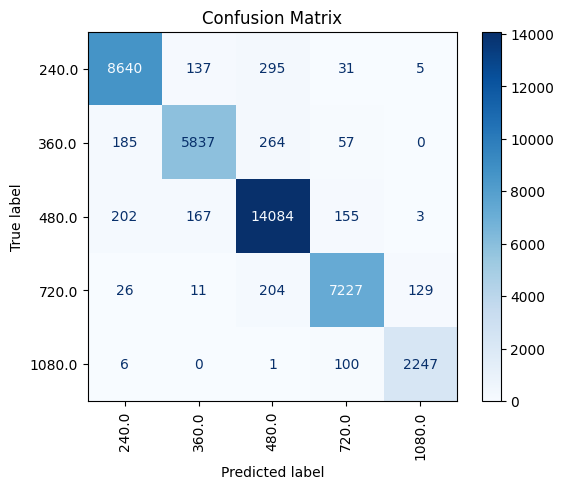

Macro ROC-AUC: 0.9967463674715156


In [20]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    classification_report
)
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

print("Accuracy:", accuracy_score(y_test, tuned_predictions))

print("Macro F1:", f1_score(y_test, tuned_predictions, average="macro"))
print("Weighted F1:", f1_score(y_test, tuned_predictions, average="weighted"))

print("\nClassification Report:")
print(classification_report(y_test, tuned_predictions))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    tuned_predictions,
    labels=best_model.classes_,
    cmap="Blues",
    xticks_rotation="vertical"
)
plt.title("Confusion Matrix")
plt.show()

y_test_binary = label_binarize(y_test, classes=best_model.classes_)
y_score = best_model.predict_proba(X_test)

from sklearn.metrics import roc_auc_score

print(
    "Macro ROC-AUC:",
    roc_auc_score(
        y_test_binary,
        y_score,
        average="macro",
        multi_class="ovr"
    )
)

## Part 3: Predict the Ongoing Resolution of a Real Netflix Session

Now that you have your model, it's time to put it in practice!

Use a preprocessed Netflix video session to infer **and plot** the resolution at 10-second time intervals. The session is `netflix_session.pkl` (downloaded in Part 2 above; 59 ten-second windows with the same 251 features as `netflix_dataset.pkl`, plus the true `resolution` so you can check yourself):

```python
session = pd.read_pickle('netflix_session.pkl')
```

In [21]:
!wget -q https://raw.githubusercontent.com/noise-courses/data/main/video-qoe/netflix_dataset.pkl.xz
!xz -df netflix_dataset.pkl.xz

/tmp/ipykernel_16415/1446555139.py:8: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  netflix_data = pickle.load(f, encoding="latin1")


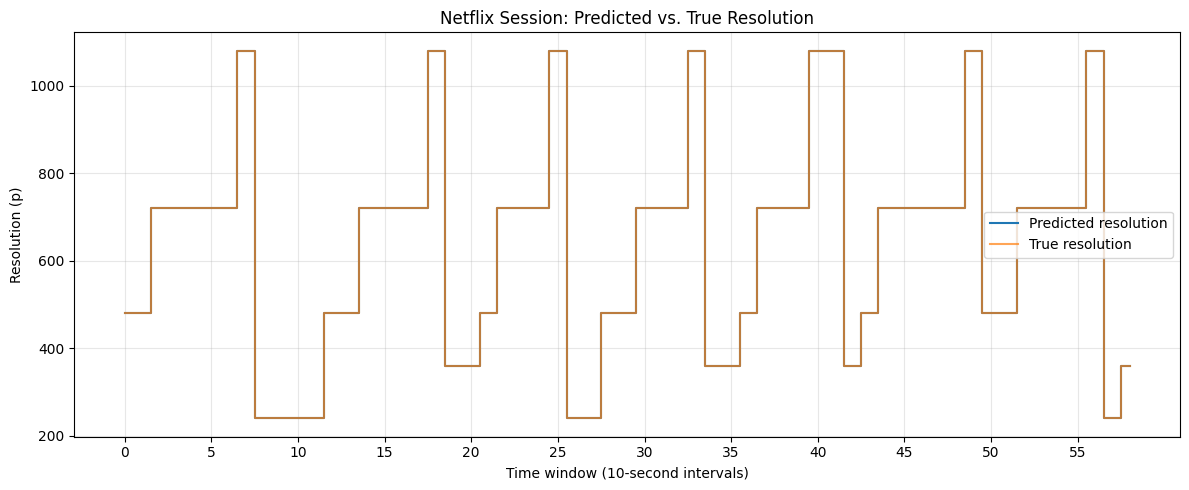

Predictions: 59
Feature count: 225
Predicted resolutions: [ 480.  480.  720.  720.  720.  720.  720. 1080.  240.  240.  240.  240.
  480.  480.  720.  720.  720.  720. 1080.  360.  360.  480.  720.  720.
  720. 1080.  240.  240.  480.  480.  720.  720.  720. 1080.  360.  360.
  480.  720.  720.  720. 1080. 1080.  360.  480.  720.  720.  720.  720.
  720. 1080.  480.  480.  720.  720.  720.  720. 1080.  240.  360.]


In [22]:
import pickle
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

with open("netflix_dataset.pkl", "rb") as f:
    netflix_data = pickle.load(f, encoding="latin1")

with open("netflix_session.pkl", "rb") as f:
    session = pickle.load(f, encoding="latin1")

valid_resolutions = [240, 360, 480, 720, 1080]
netflix_data = netflix_data[
    netflix_data["resolution"].isin(valid_resolutions)
].copy()

exclude = {"resolution", "home_id", "session_id", "video_id", "service", "index"}

feature_cols = [
    c for c in netflix_data.select_dtypes(include="number").columns
    if c not in exclude and netflix_data[c].nunique() > 1
]

X_train_p3 = netflix_data[feature_cols].fillna(0)
y_train_p3 = netflix_data["resolution"]

X_session = session.reindex(columns=feature_cols).fillna(0)

model_p3 = RandomForestClassifier(
    n_estimators=30,
    max_depth=15,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)
model_p3.fit(X_train_p3, y_train_p3)

# Predict and plot
predicted_resolution = model_p3.predict(X_session)

plt.figure(figsize=(12, 5))
plt.step(range(len(predicted_resolution)), predicted_resolution,
         where="mid", label="Predicted resolution")

if "resolution" in session.columns:
    plt.step(range(len(session)), session["resolution"],
             where="mid", label="True resolution", alpha=0.7)

plt.xlabel("Time window (10-second intervals)")
plt.ylabel("Resolution (p)")
plt.title("Netflix Session: Predicted vs. True Resolution")
plt.xticks(range(0, len(session), 5))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Predictions:", len(predicted_resolution))
print("Feature count:", len(feature_cols))
print("Predicted resolutions:", predicted_resolution)

Acknowledgments
Please fill in the following before submitting.

Collaborators: (people you discussed the assignment with, or "none")

Outside sources and code: (documentation, blog posts, repositories, etc., with links, or "none")

AI tools used: (which tool, and roughly how, e.g., "Claude Code for the netml feature extraction and debugging the pickle load", or "none")

Prompts (optional): if you're willing, add a prompts.md next to this notebook with the prompts you used. This is not graded; it helps improve the course.

In [19]:
I used AI as needed, mostly to help identify the source of bugs in my code as I went along the assignment. My prompts were along the lines of "identify the issue with this code, and point me in the right direction for solving it."